# Customer Churn: Exploratory Data Analysis and Preprocessing

Research Report: A Comparative Machine Learning Approach to Predicting Customer Churn in the Telecommunications Industry

Student: Saihil Gurupersad, ST10294145

This notebook looks at the data and cleans it up before it is used for modelling later. The dataset used is the extended IBM Telco Customer Churn dataset (IBM, 2020). It contains 7043 customer records and 33 features, including demographics, account details, the services each customer uses, and whether or not they churned.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

In [2]:
df = pd.read_excel("Telco_customer_churn.xlsx")
print("Shape:", df.shape)
df.head()

Shape: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [3]:
print(df.shape)
df.info()

(7043, 33)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 

Instead of being saved as a number, Total Charges is stored as text. This makes sense because, according to Sana et al. (2022), this feature in the Telco dataset contains missing values that are shown as blank strings rather than real nulls, which must be found and handled before the column can be used numerically. The preprocessing steps listed below address this.

Churn Reason only has 1869 non-null values out of 7043. This is not a data quality issue, only customers who churned have a reason recorded, and 1869 is close to the 26.5 percent churn rate mentioned in the proposal. This column will be dropped later regardless, since it is a leakage risk.

## Checking for Missing Values

Before any cleaning happens, the dataset is checked for missing values, including values that may be hidden as blank strings rather than proper nulls.

In [4]:
blank_count = (df["Total Charges"].astype(str).str.strip() == '').sum()
print("Blank values in Total Charges:", blank_count)

Blank values in Total Charges: 11


## Exploratory Data Analysis Plan (EDA)

This section outlines what will be explored before preprocessing begins. The following areas are covered, in order:

- Section 1: Target Variable and Class Imbalance
- Section 2: Numerical Feature Distributions
- Section 3: Numerical Features Against Churn
- Section 4: Categorical Features Against Churn
- Section 5: Correlation Between Numerical Features

# Section 1: Target Variable and Class Imbalance

This section checks the balance between customers who churned and customers who did not. Class imbalance affects how the models are trained and evaluated later, so it needs to be confirmed early (Suguna et al., 2025).

In [5]:
print(df["Churn Value"].value_counts())
print(df["Churn Value"].value_counts(normalize=True) * 100)

Churn Value
0    5174
1    1869
Name: count, dtype: int64
Churn Value
0    73.463013
1    26.536987
Name: proportion, dtype: float64


## Interpretation:
The dataset reveals a churn rate of roughly 26.5%, with 5174 customers not churning and 1869 who did. According to Geiler et al. (2022), a model that merely predicts every customer as not churning will already score approximately 73 percent accuracy without identifying a single churner. This verifies the class imbalance described in the proposal and implies that accuracy alone would not be a reliable indicator later. For this reason, the main evaluation criteria for this work are the F1 score and AUC ROC.

C:\Users\saihi\AppData\Local\Temp\ipykernel_40516\1219163583.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Churn Value", palette='pastel')


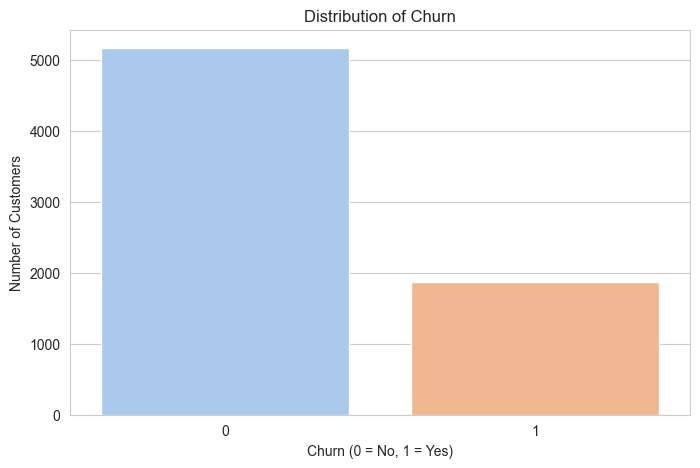

In [6]:
plt.figure()
sns.countplot(data=df, x="Churn Value", palette='pastel')
plt.title("Distribution of Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.savefig("Diagrams/churn_distribution.png", dpi=150, bbox_inches='tight')
plt.show()

Figure 1: Distribution of churned versus non churned customers. The imbalance between the two classes is clearly visible, with non churned customers making up the majority of the dataset.

# Section 2: Numerical Feature Distributions

Tenure Months, Monthly Charges, and Total Charges are the three numerical features in the dataset whose shapes are examined in this section. Because Logistic Regression is sensitive to variations in feature scale, examining these distributions aids in determining whether scaling is required prior to modelling (Sana et al., 2022).

Total Charges is still stored as text at this point, so it is converted to a number just for this plot. The actual fix for its missing values happens later in preprocessing.

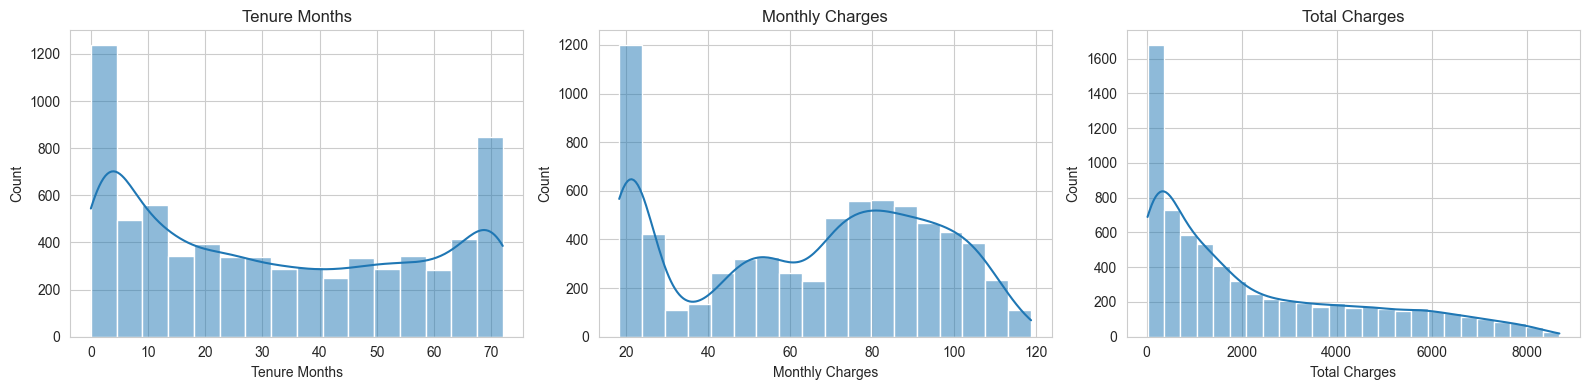

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["Tenure Months"], kde=True, ax=axes[0])
axes[0].set_title("Tenure Months")

sns.histplot(df["Monthly Charges"], kde=True, ax=axes[1])
axes[1].set_title("Monthly Charges")

sns.histplot(pd.to_numeric(df["Total Charges"], errors='coerce'), kde=True, ax=axes[2])
axes[2].set_title("Total Charges")

plt.tight_layout()
plt.savefig("Diagrams/numerical_distributions.png", dpi=150, bbox_inches='tight')
plt.show()